Import libraries

In [28]:
from sklearn.ensemble import RandomForestClassifier
import sys
from pathlib import Path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src import data_loader, metrics, feature_extractor
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import joblib


Split, Predict

In [101]:
X_train, X_val, X_test, y_train, y_val, y_test = data_loader.load_data()

# Model
rf_model = RandomForestClassifier(n_estimators=300,
                                  random_state=42,
                                  n_jobs=-1,
                                  max_depth=None,
                                  min_samples_split=4,
                                  min_samples_leaf=2,
                                  max_features="sqrt",
                                  max_samples=0.8,
                                  criterion="gini")
rf_model.fit(X_train, y_train)

#Predictions on test data
y_pred = rf_model.predict(X_test)

# Result
print(f"Accuracy:  {metrics.accuracy(y_test, y_pred)}")
print(f"Precision: {metrics.precision(y_test, y_pred)}")
print(f"Recall:    {metrics.recall(y_test, y_pred)}")
print(f"F1 Score:  {metrics.f1_score(y_test, y_pred)}")



Accuracy:  0.9972010178117048
Precision: 0.9958614573582303
Recall:    0.9992584536286335
F1 Score:  0.997557063541024


True Positive, False Positive, False Negative, True Negative

In [102]:
tp = metrics.true_positive(y_test, y_pred)
fp = metrics.false_positive(y_test, y_pred)
fn = metrics.false_negative(y_test, y_pred)
tn = metrics.true_negative(y_test, y_pred)

print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Negatives: {tn}")



True Positives: 20213
False Positives: 84
False Negatives: 15
True Negatives: 15058


Confusion Matrix

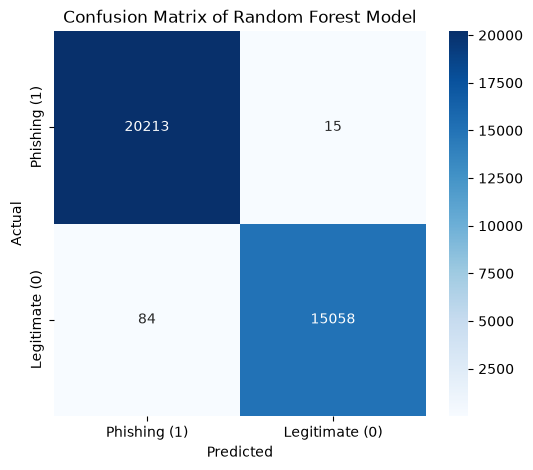

['../saved_models/random_forest_v1.joblib']

In [103]:
cm = metrics.compute_confusion_matrix(y_test, y_pred)

cm_array = np.array([
    [cm[0][0], cm[1][0]],  # [TP, FN]
    [cm[0][1], cm[1][1]]   # [FP, TN]
])

plt.figure(figsize=(6, 5))
labels = ['Phishing (1)', 'Legitimate (0)']

sns.heatmap(
    cm_array,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title('Confusion Matrix of Random Forest Model')
plt.show()



joblib.dump(rf_model, "../saved_models/random_forest_v1.joblib")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

X_inference, y_inference = feature_extractor.extract_features_from_dataset()


y_inference_prediction = rf_model.predict(X_inference)
print(classification_report(y_inference, y_inference_prediction))
print(confusion_matrix(y_inference, y_inference_prediction))